# 07 · Experimento de deriva (RQ8) e informe de monitoreo

**Pregunta (RQ8).** ¿Cómo se degrada el rendimiento ante deriva de datos, y con qué rapidez y poder la
detecta el sistema de monitoreo?

**Hipótesis pre-registrada H6.** El monitor (PSI + KS por ventana) detecta deriva de severidad ≥ 2 con
poder ≥ 0.8 y una tasa de falsas alarmas ≤ 5 % por ventana sin deriva.

**Diseño** (ver `src/project/drift_sim.py`):

1. Se toman los **modelos desplegados** del registro (`models/registry.json`) y un conjunto base de flujo
   (el test sellado en modo real). Ese conjunto se transforma con deriva controlada de severidad
   creciente:
   * Texto: vocabulario (tokens no vistos), longitud (truncamiento) y tema/prior (proporciones de clase).
   * Imágenes: desenfoque, ruido, gradiente de iluminación y tipo celular (mezcla de tipos).
2. Sobre ventanas del flujo se calculan señales de **covariables** (longitud, tasa OOV, intensidad,
   contraste, enfoque), de **predicciones** (confianza, clase predicha, número de instancias) y de
   **concepto** (métrica con etiquetas tardías).
3. Se mide el poder (curva ROC frente a intensidad), la tasa de falsas alarmas, el retardo de detección y
   la caída de la métrica asociada.

> **Modo de ejecución.** Si `data/raw` contiene los datos reales y el registro apunta a modelos entrenados
> con ellos (`trained_on: real`), el notebook usa el test sellado. En otro caso corre en **modo demo**
> con datos sintéticos y los modelos demo. Así se valida el sistema de monitoreo de punta a punta, pero
> las cifras **no** son resultados del proyecto y deben regenerarse con `make reproduce`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.config import CFG, set_global_seed
from project.drift_sim import (DEFAULT_THR, SEVERITIES, apply_alarm, build_image_pools, build_text_pools,
                               calibrate_union, delay_study, power_study, power_table, roc_auc_vs_null, wilson_ci)
from project.inference import ImagePredictor, ModelRegistry, TextPredictor
from project.text_data import tokenize

set_global_seed(CFG.seed)
ROOT = Path("..").resolve()
reg = ModelRegistry(ROOT / "models")
tm = TextPredictor.load(reg.production_dir("text"))
im = ImagePredictor.load(reg.production_dir("image"))
import os
REAL = tm.meta.get("trained_on") == "real" and (ROOT / "data/processed/nlp_splits.csv").exists()
SEG_DIR = Path(os.environ.get("SARTORIUS_DIR", ROOT / "data/raw/sartorius"))
MODE = "real" if REAL else "DEMO (sintético)"
from project.config import report_dirs
OUT_T, OUT_F = report_dirs(ROOT, REAL)
print(f"Modo: {MODE} | texto: {tm.meta['name']} | imagen: {im.meta['name']}")

I0000 00:00:1792551757.673518     604 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792551757.678781     604 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Modo: real | texto: text_nbsvm-1.1.0 | imagen: image_keras-1.1.0


## 1. Datos de referencia y del flujo

* **Referencia:** las características que el sistema guarda en el despliegue (validación del modelo).
* **Flujo base:** datos independientes de la referencia (test sellado o una muestra sintética con otra
  semilla).

In [2]:
if REAL:
    df = pd.read_csv(ROOT / "data/processed/nlp_splits.csv")          # misma partición sin fuga del bloque NLP
    df["text"] = df["text"].astype(str); df["label"] = df["label"].astype(str)
    train_txt, ref_df, stream_df = df[df.split == "train"], df[df.split == "val"], df[df.split == "test"]
else:
    from project.text_data import make_synthetic_text
    train_txt = make_synthetic_text(1200, seed=CFG.seed)            # misma semilla que el modelo demo
    ref_df, stream_df = make_synthetic_text(1000, seed=101), make_synthetic_text(1000, seed=202)
vocab = {w for t in train_txt["text"] for w in tokenize(t)}
proba = lambda tt: tm.predict_proba_batch(list(tt))
ref_pool = build_text_pools(ref_df["text"].tolist(), ref_df["label"], proba, tm.classes, vocab, severities=(0.0,), seed=1)
ref_text = ref_pool[("base", 0.0)]
text_pools = build_text_pools(stream_df["text"].tolist(), stream_df["label"], proba, tm.classes, vocab, seed=2)
print("Referencia (texto):", ref_text[["len", "oov", "conf", "correct"]].describe().loc[["mean", "std"]].round(3).to_dict())

Referencia (texto): {'len': {'mean': 797.404, 'std': 333.29}, 'oov': {'mean': 0.201, 'std': 0.068}, 'conf': {'mean': 0.711, 'std': 0.284}, 'correct': {'mean': 0.703, 'std': 0.457}}


## 2. Poder de detección y falsas alarmas (texto)

Ventanas de 200 solicitudes (muestreadas sin reemplazo del pool) y 200 réplicas por tipo y severidad.
Con los **umbrales por defecto**, el monitor da alarma si el PSI máximo supera 0.2, si el p mínimo de KS
(Bonferroni) baja de 0.01 o si el χ² de la clase predicha baja de 0.01. Se reporta también el poder con
**umbrales calibrados por simulación**: una corrida nula independiente (otra semilla) fija la tasa de
falsas alarmas de la unión de señales en 5 %.

In [3]:
FEATS_T, CAT_T = ["len", "oov", "conf"], ["pred"]
null_cal = power_study(ref_text, text_pools, [], FEATS_T, CAT_T, window=200, reps=400, seed=99,
                       prior_kind="tema", severities=(0.0,))
thr_t = calibrate_union(null_cal, 0.05)
res_t = power_study(ref_text, text_pools, ["vocabulario", "longitud"], FEATS_T, CAT_T, window=200, reps=200, seed=3)
res_t["alarma_calibrada"] = apply_alarm(res_t, thr_t)
pt = power_table(res_t)
pt_cal = power_table(res_t, "alarma_calibrada")[["tipo", "severidad", "tasa_alarma"]].rename(columns={"tasa_alarma": "poder_calibrado"})
pt = pt.merge(pt_cal, on=["tipo", "severidad"])
auc_t = roc_auc_vs_null(res_t)
print("Umbrales calibrados (texto, FPR 5 %):", {k: round(v, 4) for k, v in thr_t.items()})
print(pt.round(3).to_string(index=False))
pt.to_csv(OUT_T / "drift_text_power.csv", index=False); auc_t.to_csv(OUT_T / "drift_text_auc.csv", index=False)

Umbrales calibrados (texto, FPR 5 %): {'psi': 0.1799, 'ks': 0.0677, 'chi2': 0.4876}
       tipo  severidad  tasa_alarma  ic_low  ic_high  metrica_media  poder_calibrado
   longitud        0.0        0.000   0.000    0.019          0.712            0.060
   longitud        0.1        0.865   0.811    0.906          0.708            1.000
   longitud        0.2        1.000   0.981    1.000          0.711            1.000
   longitud        0.3        1.000   0.981    1.000          0.721            1.000
   longitud        0.5        1.000   0.981    1.000          0.716            1.000
   longitud        0.8        1.000   0.981    1.000          0.696            1.000
       tema        0.0        0.005   0.001    0.028          0.714            0.050
       tema        0.1        0.110   0.074    0.161          0.721            0.840
       tema        0.2        0.855   0.800    0.897          0.732            1.000
       tema        0.3        1.000   0.981    1.000          0.74

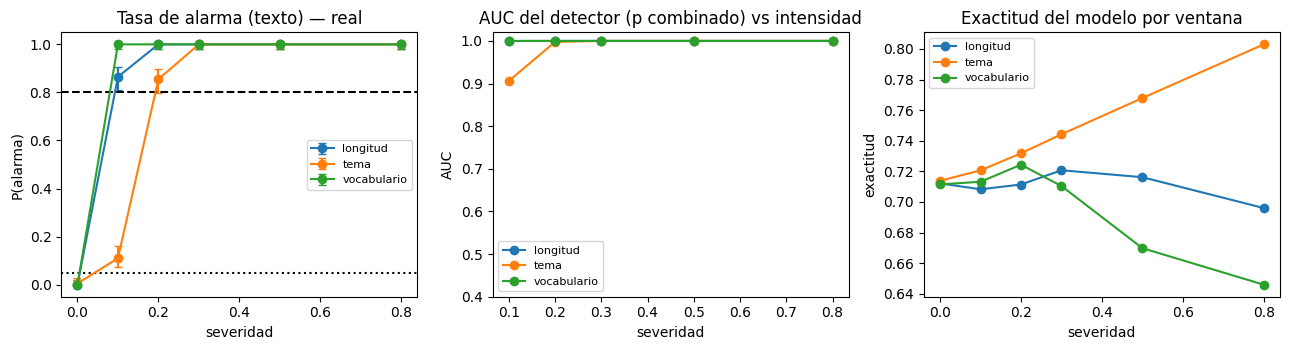

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, g in pt.groupby("tipo"):
    ax[0].errorbar(g.severidad, g.tasa_alarma, yerr=[g.tasa_alarma - g.ic_low, g.ic_high - g.tasa_alarma], marker="o", capsize=3, label=k)
    ax[2].plot(g.severidad, g.metrica_media, "o-", label=k)
for k, g in auc_t.groupby("tipo"):
    ax[1].plot(g.severidad, g.auc_score_comb, "o-", label=k)
ax[0].axhline(0.05, ls=":", c="k"); ax[0].axhline(0.8, ls="--", c="k")
ax[0].set(title=f"Tasa de alarma (texto) — {MODE}", xlabel="severidad", ylabel="P(alarma)")
ax[1].set(title="AUC del detector (p combinado) vs intensidad", xlabel="severidad", ylabel="AUC"); ax[1].set_ylim(0.4, 1.02)
ax[2].set(title="Exactitud del modelo por ventana", xlabel="severidad", ylabel="exactitud")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_F / "drift_text_power.png", dpi=120)

## 3. Imágenes: desenfoque, ruido, iluminación y tipo celular

Ventanas de 50 imágenes. Características: intensidad media, contraste (DE), enfoque (varianza del
Laplaciano) y número de instancias predichas. La métrica con etiquetas tardías es AP@[0.5:0.95] por
imagen.

In [5]:
if REAL:
    from project.data_seg import build_image_table, label_map_for, load_annotations, read_image
    ann = load_annotations(SEG_DIR / "train.csv")
    tab = build_image_table(ann, SEG_DIR / "train").merge(pd.read_csv(ROOT / "data/processed/seg_splits.csv")[["id_imagen", "split"]], on="id_imagen")
    sp = tab.split
    def load(sub):
        return ([read_image(p) for p in sub.ruta_imagen], [label_map_for(ann, i) for i in sub.id_imagen], sub.tipo_celular.tolist())
    ref_imgs, ref_lbls, ref_ct = load(tab[sp == "val"]); st_imgs, st_lbls, st_ct = load(tab[sp == "test"])
else:
    from project.data_seg import make_synthetic_dataset
    ref_imgs, ref_lbls, m1 = make_synthetic_dataset(50, shape=(96, 128), seed=11)
    st_imgs, st_lbls, m2 = make_synthetic_dataset(50, shape=(96, 128), seed=12)
    ref_ct, st_ct = m1.tipo_celular.tolist(), m2.tipo_celular.tolist()
ref_img = build_image_pools(ref_imgs, ref_lbls, ref_ct, im.predict_label_map, n_levels=1, seed=4)[("base", 0.0)]
img_pools = build_image_pools(st_imgs, st_lbls, st_ct, im.predict_label_map, seed=5)
FEATS_I = ["mean", "std", "lapvar", "n_pred"]
kw_i = dict(window=50, prior_kind="tipo_celular", target_class="shsy5y")   # deriva de tipo celular hacia shsy5y
null_cal_i = power_study(ref_img, img_pools, [], FEATS_I, (), reps=400, seed=98, severities=(0.0,), **kw_i)
thr_i = calibrate_union(null_cal_i, 0.05)
res_i = power_study(ref_img, img_pools, ["blur", "noise", "illumination"], FEATS_I, (), reps=200, seed=6, **kw_i)
res_i["alarma_calibrada"] = apply_alarm(res_i, thr_i)
pi_ = power_table(res_i).merge(power_table(res_i, "alarma_calibrada")[["tipo", "severidad", "tasa_alarma"]]
                               .rename(columns={"tasa_alarma": "poder_calibrado"}), on=["tipo", "severidad"])
auc_i = roc_auc_vs_null(res_i)
print("Umbrales calibrados (imágenes, FPR 5 %):", {k: round(v, 4) for k, v in thr_i.items()})
print(pi_.round(3).to_string(index=False))
pi_.to_csv(OUT_T / "drift_image_power.csv", index=False); auc_i.to_csv(OUT_T / "drift_image_auc.csv", index=False)

Umbrales calibrados (imágenes, FPR 5 %): {'psi': 0.4922, 'ks': 0.0488, 'chi2': 0.0}
        tipo  severidad  tasa_alarma  ic_low  ic_high  metrica_media  poder_calibrado
        blur        0.0        0.755   0.691    0.809          0.162            0.040
        blur        0.1        1.000   0.981    1.000          0.159            1.000
        blur        0.2        1.000   0.981    1.000          0.143            1.000
        blur        0.3        1.000   0.981    1.000          0.103            1.000
        blur        0.5        1.000   0.981    1.000          0.043            1.000
        blur        0.8        1.000   0.981    1.000          0.014            1.000
illumination        0.0        0.715   0.649    0.773          0.161            0.035
illumination        0.1        1.000   0.981    1.000          0.161            1.000
illumination        0.2        1.000   0.981    1.000          0.160            1.000
illumination        0.3        1.000   0.981    1.000   

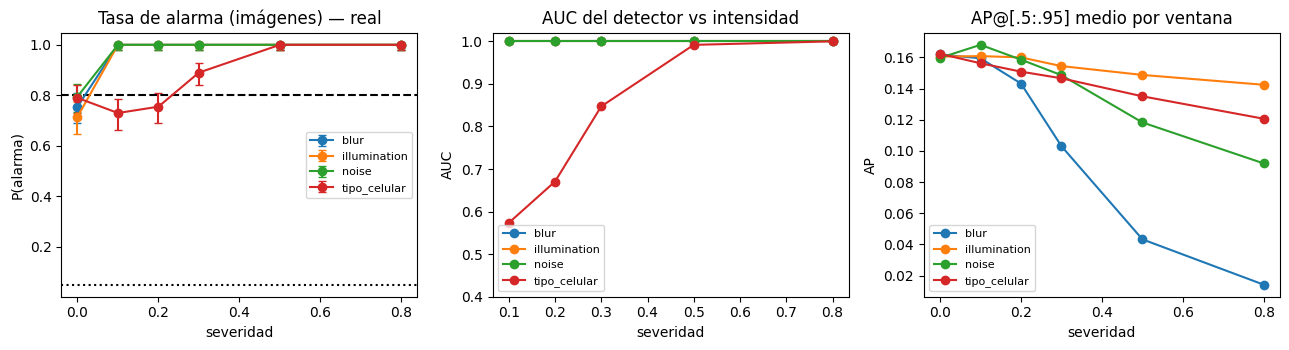

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, g in pi_.groupby("tipo"):
    ax[0].errorbar(g.severidad, g.tasa_alarma, yerr=[g.tasa_alarma - g.ic_low, g.ic_high - g.tasa_alarma], marker="o", capsize=3, label=k)
    ax[2].plot(g.severidad, g.metrica_media, "o-", label=k)
for k, g in auc_i.groupby("tipo"):
    ax[1].plot(g.severidad, g.auc_score_comb, "o-", label=k)
ax[0].axhline(0.05, ls=":", c="k"); ax[0].axhline(0.8, ls="--", c="k")
ax[0].set(title=f"Tasa de alarma (imágenes) — {MODE}", xlabel="severidad", ylabel="P(alarma)")
ax[1].set(title="AUC del detector vs intensidad", xlabel="severidad", ylabel="AUC"); ax[1].set_ylim(0.4, 1.02)
ax[2].set(title="AP@[.5:.95] medio por ventana", xlabel="severidad", ylabel="AP")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_F / "drift_image_power.png", dpi=120)

## 4. Retardo de detección con deriva gradual

El flujo tiene 30 ventanas. La deriva empieza en la ventana 10 y su severidad sube linealmente hasta la
máxima en 10 ventanas. Se comparan dos políticas de alarma: paciencia 1 (alarma inmediata) y paciencia 2
(dos ventanas consecutivas). Se hacen 100 réplicas por política.

In [7]:
rows = []
cfgs = (("texto", ref_text, text_pools, "vocabulario", FEATS_T, CAT_T, 200, thr_t, {}),
        ("texto", ref_text, text_pools, "tema", FEATS_T, CAT_T, 200, thr_t, {}),
        ("imagen", ref_img, img_pools, "blur", FEATS_I, (), 50, thr_i, {}),
        ("imagen", ref_img, img_pools, "tipo_celular", FEATS_I, (), 50, thr_i,
         dict(prior_kind="tipo_celular", target_class="shsy5y")))
for dom, ref, pools, kind, feats, cat, win, thr, extra in cfgs:
    for pat in (1, 2):
        d = delay_study(ref, pools, kind, feats, cat, window=win, patience=pat, reps=100, seed=8, thr=thr, **extra)
        det = d[d.detectada]
        rows.append(dict(dominio=dom, deriva=kind, paciencia=pat, tasa_deteccion=d.detectada.mean(),
                         retardo_mediano=det.retardo.median(), retardo_p90=det.retardo.quantile(0.9),
                         falsas_alarmas_previas_media=d.falsas_alarmas_previas.mean(),
                         caida_metrica_en_deteccion=det.caida_metrica_en_deteccion.mean(),
                         caida_metrica_final=d.caida_metrica_final.mean()))
delay = pd.DataFrame(rows)
print(delay.round(3).to_string(index=False))
delay.to_csv(OUT_T / "drift_delay.csv", index=False)

dominio       deriva  paciencia  tasa_deteccion  retardo_mediano  retardo_p90  falsas_alarmas_previas_media  caida_metrica_en_deteccion  caida_metrica_final
  texto  vocabulario          1             1.0              0.0          0.0                          0.39                      -0.001                0.068
  texto  vocabulario          2             1.0              1.0          1.0                          0.01                      -0.015                0.068
  texto         tema          1             1.0              0.0          1.0                          0.43                      -0.014               -0.090
  texto         tema          2             1.0              1.0          2.0                          0.02                      -0.026               -0.090
 imagen         blur          1             1.0              0.0          0.0                          0.43                      -0.001                0.146
 imagen         blur          2             1.0           

## 5. Contraste de H6 y política de alerta

H6 se evalúa por tipo de deriva con los dos juegos de umbrales: los **por defecto** (los declarados en el
pre-registro) y los **calibrados**, que se reportan como análisis secundario. Para cada uno se calcula el
poder a severidad ≥ 2 (aquí, s = 0.2) y la tasa de falsas alarmas a severidad 0, con IC de Wilson.

In [8]:
def h6_rows(res, dom, col):
    out = []
    for k, g in res.groupby("tipo"):
        null, g2 = g[g.severidad == 0], g[g.severidad == SEVERITIES[2]]
        fpr = wilson_ci(int(null[col].sum()), len(null)); pw = wilson_ci(int(g2[col].sum()), len(g2))
        out.append(dict(dominio=dom, umbrales="calibrados" if col != "alarma" else "por defecto", deriva=k,
                        poder_s2=pw[0], poder_ic=f"[{pw[1]:.2f}, {pw[2]:.2f}]",
                        fpr=fpr[0], fpr_ic=f"[{fpr[1]:.3f}, {fpr[2]:.3f}]",
                        H6=("apoyada" if pw[1] >= 0.8 and fpr[2] <= 0.05 else
                            "refutada" if pw[2] < 0.8 or fpr[1] > 0.05 else "no concluyente")))
    return out
h6 = pd.DataFrame(h6_rows(res_t, "texto", "alarma") + h6_rows(res_i, "imagen", "alarma")
                  + h6_rows(res_t, "texto", "alarma_calibrada") + h6_rows(res_i, "imagen", "alarma_calibrada"))
print(h6.to_string(index=False))
h6.to_csv(OUT_T / "drift_h6.csv", index=False)
summary = dict(modo=MODE, umbrales_calibrados_texto=thr_t, umbrales_calibrados_imagen=thr_i,
               h6=h6.to_dict("records"), retardo=delay.to_dict("records"))
_ = (OUT_T / "drift_summary.json").write_text(json.dumps(summary, indent=2, default=float))

dominio    umbrales       deriva  poder_s2     poder_ic   fpr         fpr_ic             H6
  texto por defecto     longitud     1.000 [0.98, 1.00] 0.000 [0.000, 0.019]        apoyada
  texto por defecto         tema     0.855 [0.80, 0.90] 0.005 [0.001, 0.028] no concluyente
  texto por defecto  vocabulario     1.000 [0.98, 1.00] 0.000 [0.000, 0.019]        apoyada
 imagen por defecto         blur     1.000 [0.98, 1.00] 0.755 [0.691, 0.809]       refutada
 imagen por defecto illumination     1.000 [0.98, 1.00] 0.715 [0.649, 0.773]       refutada
 imagen por defecto        noise     1.000 [0.98, 1.00] 0.795 [0.734, 0.845]       refutada
 imagen por defecto tipo_celular     0.755 [0.69, 0.81] 0.790 [0.728, 0.841]       refutada
  texto  calibrados     longitud     1.000 [0.98, 1.00] 0.060 [0.035, 0.102] no concluyente
  texto  calibrados         tema     1.000 [0.98, 1.00] 0.050 [0.027, 0.090] no concluyente
  texto  calibrados  vocabulario     1.000 [0.98, 1.00] 0.025 [0.011, 0.057] no 

### Política de alerta y reentrenamiento (propuesta)

**Lectura de los resultados** (se actualiza al re-ejecutar con los modelos reales):

* Los umbrales fijos de la literatura (PSI 0.2, KS 0.01) **no garantizan** la tasa de falsas alarmas
  pre-registrada. Esa tasa depende del tamaño de ventana y del número de señales: con ventanas pequeñas,
  como las de 50 imágenes, el PSI es ruidoso. Por eso el umbral operativo se **calibra por simulación** al
  percentil 95 de la distribución nula de cada señal y del tamaño de ventana real.
* Las derivas que cambian la distribución de entrada (vocabulario, desenfoque, iluminación) se detectan
  con mucho poder **antes** de que la métrica caiga de forma apreciable. Las que solo cambian la mezcla de
  clases (tema/prior, tipo celular) se detectan sobre todo por la deriva de predicciones (χ² de la clase
  predicha, número de instancias) y pueden alterar la métrica global sin degradar el modelo por clase.
* La paciencia 2 reduce las falsas alarmas previas a costa de aproximadamente una ventana de retardo
  adicional.

**Política:**

| Nivel | Condición | Acción |
|---|---|---|
| Aviso | 1 ventana con alarma (umbral calibrado) | Registrar; muestrear 50 casos para etiquetado prioritario |
| Alerta | 2 ventanas consecutivas **o** caída de la métrica con etiquetas tardías > δ (Page–Hinkley) | Revisión humana; activar modelo candidato en **shadow** |
| Crítico | Alerta + caída de la métrica > 2δ o tasa de errores operacionales > 1 % | **Rollback** al modelo anterior del registro y reentrenamiento con datos recientes |

**Costos.** Un falso positivo cuesta horas de revisión (≈ 1 h-persona por alerta). Un falso negativo
en reclutamiento puede costar decisiones sesgadas o erróneas sobre personas, y en microscopía, conteos
celulares inválidos en un experimento. Por eso se prioriza el poder en el nivel «Aviso» (barato) y la
especificidad en los niveles que disparan acciones costosas.

**Despliegue.** Todo modelo reentrenado pasa por (1) la prueba de regresión del conjunto dorado en CI,
(2) **shadow** durante ≥ 2 ventanas comparando predicciones con producción, (3) **canary** al 10 % del
tráfico con rollback automático si la latencia p95 o la tasa de errores empeoran, y (4) promoción en el
registro (`ModelRegistry.promote`), conservando la versión previa para **rollback**
(`ModelRegistry.rollback`).